# MAKE_VIDEO · story text → cartoon video

**To make a new video**
1. Copy a file in `stories/` (for example `1_golden_mango.txt`), give it a new name, and write your own story in it  
   (format: see `SYNTAX.md` - it is just names, feelings and lines of dialogue).
2. Change `STORY` in the first cell below to your file.
3. Menu **Run → Run All Cells**. The video appears in `output/`.

Voices are made with free Microsoft neural voices (**internet needed once per new line**). Lines you did not change are reused, so editing a story is fast.

In [1]:
STORY = "stories/islamic/17.txt"     # <- change to your story file. Islamic videos: stories/islamic/...   Folk tales: stories/1_golden_mango.txt ...

USE_DRAFT_VOICE_IF_OFFLINE = False        # True = if real voices fail, use a humming PLACEHOLDER (testing only!)

## 1 · Check this computer

In [2]:
# First time only (or if something is missing): remove the # on the next line and run this cell, then restart the kernel.
# %pip install -U edge-tts uharfbuzz pillow numpy fonttools

from engine import check_setup
check_setup()

  OK   ffmpeg installed
  OK   Pillow 12.3.0
  OK   Bangla text shaping (uharfbuzz - built-in fix)
  OK   numpy
  OK   fontTools
  OK   edge_tts
  OK   fonts/NotoSansBengali-Bold.ttf

Ready to go.


True

## 2 · Read the story

In [3]:
from engine.script import load_story, describe, ScriptError

try:
    story = load_story(STORY)
except ScriptError as e:
    print("PROBLEM IN YOUR STORY FILE\n")
    print(e)
    raise SystemExit("Fix the story file and run this cell again.")
describe(story)

Title: মা-বাবার দোয়া
Characters: hujur (হুজুর), baba (বাবা), ma (মা), child (আরিফ), girl (আয়েশা), student (রাফি)
Scenes: 6   Spoken lines: 66   Estimated length: about 366 seconds


## 3 · Voices
Makes one voice file per line in `audio/`. Each character gets its own voice, speed, pitch and a *voice effect* (`fx`) that makes the voice deeper or higher, so characters sound different.  
Lines that already have a voice are skipped. Want to use your **own recording** instead? Save it as `audio/line_03.mp3` (the line number) - it is used automatically.

In [4]:
import asyncio, edge_tts
from pathlib import Path
from engine import audio

async def safe_edge_provider(text, voice, emotion, out_path):
    out_path = Path(out_path)
    rate, pitch = audio.tts_settings(voice, emotion)
    last = None
    for r, p in [(rate, pitch), (rate, "+0Hz"), ("+0%", "+0Hz")]:
        try:
            await edge_tts.Communicate(text, voice["name"], rate=r, pitch=p).save(str(out_path))
            if out_path.exists() and out_path.stat().st_size > 1000:
                return
        except Exception as e:
            last = e
            await asyncio.sleep(1)
    raise RuntimeError(f"No audio even with plain settings: {last}")

await audio.tts_all(story, "audio", provider=safe_edge_provider)

  have   line_01_266953
  have   line_02_c9e4ea
  have   line_03_da660c
  have   line_04_ec71af
  have   line_05_4e2f1f
  have   line_06_4e511e
  have   line_07_4265f1
  have   line_08_545535
  have   line_09_eccbde
  have   line_10_33f4fd
  have   line_11_01280e
  have   line_12_9aa46f
  have   line_13_7db5cf
  have   line_14_8c2fe9
  have   line_15_b9e398
  have   line_16_3f951b
  have   line_17_b05241
  have   line_18_5c4f4c
  have   line_19_12f44e
  have   line_20_51e6bd
  have   line_21_ce0b33
  have   line_22_754df6
  have   line_23_d38e78
  have   line_24_c5dfdf
  have   line_25_01df40
  have   line_26_67cf97
  have   line_27_322b5e
  have   line_28_ef45b3
  have   line_29_72fe2b
  have   line_30_5f4cdd
  have   line_31_14408f
  have   line_32_a8c071
  have   line_33_81ea44
  have   line_34_626100
  have   line_35_bd5a03
  have   line_36_290faa
  have   line_37_2740fe
  have   line_38_9ce3d7
  have   line_39_c8aeee
  have   line_40_78fa17
  have   line_41_26b32c
  have   line_42

In [5]:
from engine import audio
import traceback

print("Making voices (lines that already have one are skipped)...")

tts_error = None
try:
    # More natural paid voices (ElevenLabs / Google): see engine/voices_pro.py, then use  provider=..., fx=False
    await audio.tts_all(story, "audio")
except Exception as e:
    tts_error = e
    print("\nTTS ERROR:")
    traceback.print_exc()
    if USE_DRAFT_VOICE_IF_OFFLINE:
        print("\nMaking placeholder hum voices (NOT real speech) so you can test the animation.")
        audio.make_all_draft_audio(story, "audio")

status = audio.audio_status(story, "audio")

print("\n========== AUDIO STATUS ==========")
for lid, who, state, text in status:
    mark = {"real": "OK", "draft": "DRAFT", "missing": "MISSING"}.get(state, "UNKNOWN")
    print(f"{mark:8} | {lid:16} | {who:10} | {text[:60]}")

missing = [s for s in status if s[2] == "missing"]
draft = [s for s in status if s[2] == "draft"]
real = [s for s in status if s[2] == "real"]

print("\n========== SUMMARY ==========")
print("Real voices:   ", len(real))
print("Draft voices:  ", len(draft), "(humming placeholder - not real speech)" if draft else "")
print("Missing voices:", len(missing))

if missing:
    print("\nMissing dialogue:")
    for item in missing:
        print(" ", item[0], "-", item[1], "-", item[3][:80])
    raise SystemExit("Stopped: some lines have no voice yet. Fix the error above (internet? edge-tts installed?) and run this cell again.")
print("\nAll dialogue lines have audio!")

Making voices (lines that already have one are skipped)...
  have   line_01_266953
  have   line_02_c9e4ea
  have   line_03_da660c
  have   line_04_ec71af
  have   line_05_4e2f1f
  have   line_06_4e511e
  have   line_07_4265f1
  have   line_08_545535
  have   line_09_eccbde
  have   line_10_33f4fd
  have   line_11_01280e
  have   line_12_9aa46f
  have   line_13_7db5cf
  have   line_14_8c2fe9
  have   line_15_b9e398
  have   line_16_3f951b
  have   line_17_b05241
  have   line_18_5c4f4c
  have   line_19_12f44e
  have   line_20_51e6bd
  have   line_21_ce0b33
  have   line_22_754df6
  have   line_23_d38e78
  have   line_24_c5dfdf
  have   line_25_01df40
  have   line_26_67cf97
  have   line_27_322b5e
  have   line_28_ef45b3
  have   line_29_72fe2b
  have   line_30_5f4cdd
  have   line_31_14408f
  have   line_32_a8c071
  have   line_33_81ea44
  have   line_34_626100
  have   line_35_bd5a03
  have   line_36_290faa
  have   line_37_2740fe
  have   line_38_9ce3d7
  have   line_39_c8aeee
  hav

Listen to the first lines:

In [6]:
from IPython.display import Audio, display
for lid, who, state, text in status[:3]:
    p = audio.find_audio("audio", lid)
    if p:
        print(who, "-", text[:50])
        display(Audio(str(p)))

ma - আরিফ বাবা, ওঠো! সকাল হয়ে গেছে। স্কুলে যাওয়ার সময


child - আম্মু, আর পাঁচ মিনিট ঘুমাই! স্বপ্নে দেখছিলাম আমি এ


girl - ভাইয়া, চকলেটের পাহাড়ে উঠলে তো পড়ে গিয়ে পেট ব্য


## 4 · Preview some frames (quick, no video yet)

In [7]:
# %pip install fonttools

In [8]:
from fontTools.pens.basePen import BasePen
from fontTools.pens.svgPathPen import SVGPathPen

print("BasePen:", BasePen)
print("SVGPathPen:", SVGPathPen)

BasePen: <class 'fontTools.pens.basePen.BasePen'>
SVGPathPen: <class 'fontTools.pens.svgPathPen.SVGPathPen'>


Video length: 441 seconds (7.4 min)


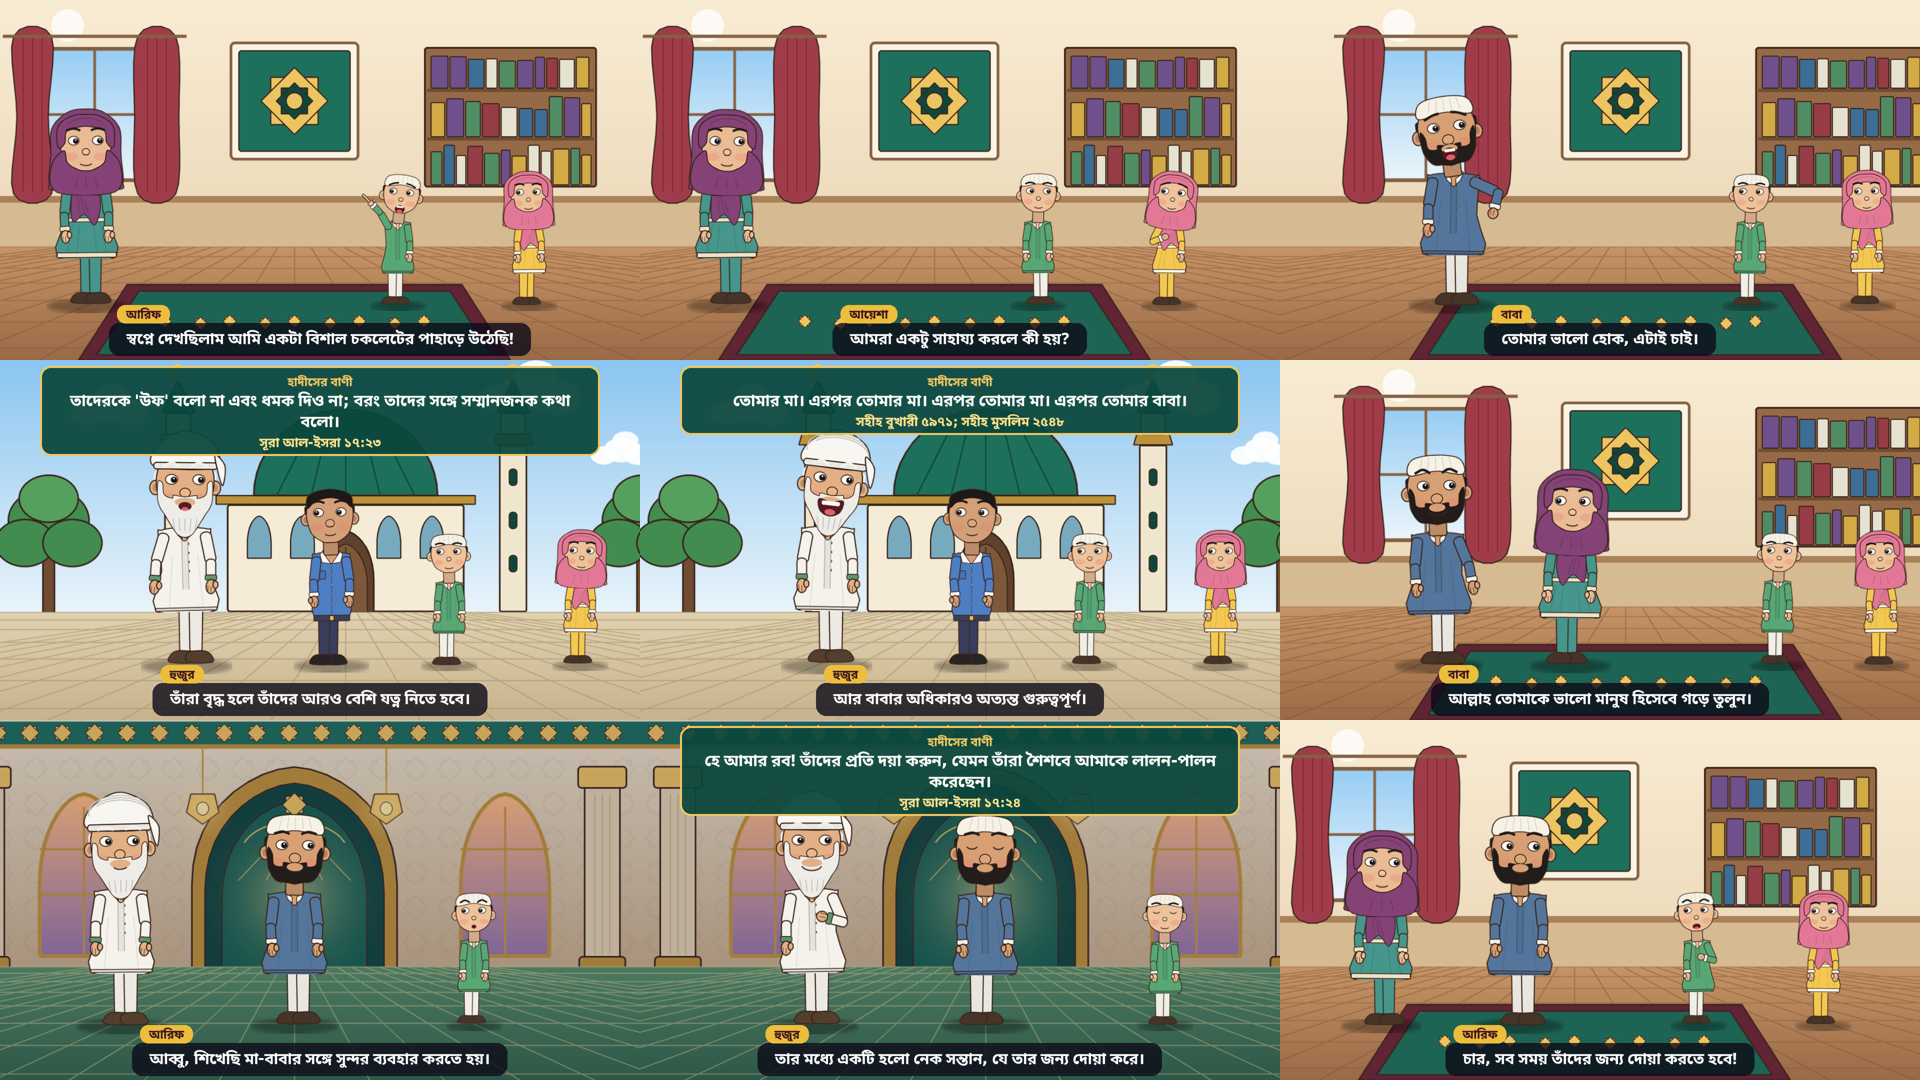

In [9]:
# from engine.render import Studio

# studio = Studio(".", STORY, draft=USE_DRAFT_VOICE_IF_OFFLINE)
# total = studio.tl.total
# print(f"Video length: {total:.0f} seconds ({total / 60:.1f} min)")
# times = [total * f for f in (0.03, 0.12, 0.25, 0.38, 0.5, 0.62, 0.75, 0.88, 0.97)]
# studio.contact_sheet(times, cols=3, scale=0.5)

from engine.render import Studio

studio = Studio(".", STORY, draft=USE_DRAFT_VOICE_IF_OFFLINE)

total = studio.tl.total
print(f"Video length: {total:.0f} seconds ({total / 60:.1f} min)")

times = [
    total * f
    for f in (0.03, 0.12, 0.25, 0.38, 0.5, 0.62, 0.75, 0.88, 0.97)
]

studio.contact_sheet(times, cols=3, scale=0.5)

## 5 · Render the video
About 1–2 minutes for a 2 minute video.  
Optional background music: put a file at `music/music.mp3`. It is mixed in quietly, becomes softer while someone speaks, and fades in and out.

In [10]:
from pathlib import Path
from IPython.display import Video

out = f"output/{Path(STORY).stem}.mp4"
studio.render(out)
Video(out, width=800)

     0.0s / 441.2s  (  0%)  elapsed    0s
    10.0s / 441.2s  (  2%)  elapsed    4s
    20.0s / 441.2s  (  5%)  elapsed    8s
    30.0s / 441.2s  (  7%)  elapsed   12s
    40.0s / 441.2s  (  9%)  elapsed   17s
    50.0s / 441.2s  ( 11%)  elapsed   21s
    60.0s / 441.2s  ( 14%)  elapsed   26s
    70.0s / 441.2s  ( 16%)  elapsed   31s
    80.0s / 441.2s  ( 18%)  elapsed   36s
    90.0s / 441.2s  ( 20%)  elapsed   40s
   100.0s / 441.2s  ( 23%)  elapsed   45s
   110.0s / 441.2s  ( 25%)  elapsed   50s
   120.0s / 441.2s  ( 27%)  elapsed   55s
   130.0s / 441.2s  ( 29%)  elapsed   61s
   140.0s / 441.2s  ( 32%)  elapsed   68s
   150.0s / 441.2s  ( 34%)  elapsed   73s
   160.0s / 441.2s  ( 36%)  elapsed   78s
   170.0s / 441.2s  ( 39%)  elapsed   84s
   180.0s / 441.2s  ( 41%)  elapsed   89s
   190.0s / 441.2s  ( 43%)  elapsed   94s
   200.0s / 441.2s  ( 45%)  elapsed  100s
   210.0s / 441.2s  ( 48%)  elapsed  105s
   220.0s / 441.2s  ( 50%)  elapsed  109s
   230.0s / 441.2s  ( 52%)  elapse

## Housekeeping (optional)
Shows voice files that the current story no longer uses. Set `delete=True` to remove them.

In [11]:
audio.clean_unused_audio(story, "audio", delete=False)

unused  .gitignore
unused  .gitkeep
unused  line_01_0a9920.draft.wav
unused  line_01_0d3f49.draft.wav
unused  line_01_2a05bd.draft.wav
unused  line_01_4d447b.mp3
unused  line_01_506ff2.mp3
unused  line_01_58d2de.mp3
unused  line_01_7b2274.mp3
unused  line_01_b4695c.mp3
unused  line_01_c6f841.mp3
unused  line_01_eff06c.draft.wav
unused  line_01_fa8c6c.draft.wav
unused  line_02_0b12f0.draft.wav
unused  line_02_231c44.mp3
unused  line_02_2f2609.mp3
unused  line_02_362fe4.draft.wav
unused  line_02_3cc8a8.mp3
unused  line_02_3def2c.mp3
unused  line_02_47658f.draft.wav
unused  line_02_796cf6.mp3
unused  line_02_90905e.draft.wav
unused  line_02_e24771.draft.wav
unused  line_02_e6586d.draft.wav
unused  line_02_f63d3a.mp3
unused  line_02_f9373e.draft.wav
unused  line_03_084406.draft.wav
unused  line_03_275fb6.draft.wav
unused  line_03_4225e6.draft.wav
unused  line_03_517818.mp3
unused  line_03_775eae.mp3
unused  line_03_81e635.draft.wav
unused  line_03_8ee159.draft.wav
unused  line_03_ba0cf7.mp

[PosixPath('audio/.gitignore'),
 PosixPath('audio/.gitkeep'),
 PosixPath('audio/line_01_0a9920.draft.wav'),
 PosixPath('audio/line_01_0d3f49.draft.wav'),
 PosixPath('audio/line_01_2a05bd.draft.wav'),
 PosixPath('audio/line_01_4d447b.mp3'),
 PosixPath('audio/line_01_506ff2.mp3'),
 PosixPath('audio/line_01_58d2de.mp3'),
 PosixPath('audio/line_01_7b2274.mp3'),
 PosixPath('audio/line_01_b4695c.mp3'),
 PosixPath('audio/line_01_c6f841.mp3'),
 PosixPath('audio/line_01_eff06c.draft.wav'),
 PosixPath('audio/line_01_fa8c6c.draft.wav'),
 PosixPath('audio/line_02_0b12f0.draft.wav'),
 PosixPath('audio/line_02_231c44.mp3'),
 PosixPath('audio/line_02_2f2609.mp3'),
 PosixPath('audio/line_02_362fe4.draft.wav'),
 PosixPath('audio/line_02_3cc8a8.mp3'),
 PosixPath('audio/line_02_3def2c.mp3'),
 PosixPath('audio/line_02_47658f.draft.wav'),
 PosixPath('audio/line_02_796cf6.mp3'),
 PosixPath('audio/line_02_90905e.draft.wav'),
 PosixPath('audio/line_02_e24771.draft.wav'),
 PosixPath('audio/line_02_e6586d.draft